# 05 MACHINE LEARNING - BASICS - REVIEW EXERCISE - CONCRETE COMPRESSION STRENGTH

---

## scikit-learn machine learning pipeline with validation

---

(concrete compressive strength dataset)

### Task 1 : Import libraries

Import the necessary libraries (pandas, Numpy, Matplotlib, Seaborn and scikit-learn libraries)

In [1]:
# SOLUTION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

### Task 2 : Set Seaborn style

Choose a seaborn style for plots.

In [5]:
# SOLUTION
sns.set()

### Task 3 : Load the data

Load the 'Concrete_Data.csv' from the data directory and display the first rows.

In [4]:
# SOLUTION
df = pd.read_csv('data/Concrete_Data.csv')
# Display the first few rows to understand the structure of the dataset
df.head()

,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


### Task 4 : Key statistics and missing values

Understand the dataset by displaying key statistics and check for missing values

In [7]:
#SOLUTION
# Key statistics
display(df.describe())
# Count the number of missing values per column
print(df.isnull().sum())

,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


cement              0
slag                0
flyash              0
water               0
superplasticizer    0
coarseaggregate     0
fineaggregate       0
age                 0
csMPa               0
dtype: int64


### Task 5 : Heatmap with correlations

Plot a heatmap of the correlation matrix to understand the relationships between the target variable 'csMPa' and all other variables (predictors).

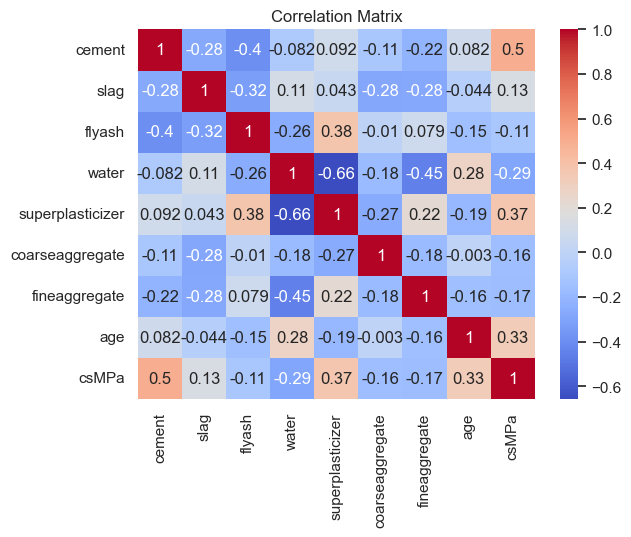

In [8]:
#SOLUTION
# plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


### Task 6 : Simple linear regression

Perform a simple linear regression with 'csMPa' as target and one feature.

What feature seems to be the best candidate for the job?

Use a standard test setup (training set and test set) and make the predictions 
for the observations in the test set.

In [9]:
#SOLUTION

# Select the feature (X) and the target variable (y)
# 'cement' has the highest correlation with 'csMPa' and hence is the best 
# candidate.
X = df[['cement']] # Results in a dataframe
y = df['csMPa']

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Create a linear regression model
lin_reg_one = LinearRegression()

# Train the model
lin_reg_one.fit(X_train, y_train)

# Predict the test set
y_pred_one = lin_reg_one.predict(X_test)

### Task 7 : Validation

Calculate and display the R-squared and Mean Squared Error (MSE) for the simple linear regression.

In [10]:
#SOLUTION
print(f'R-squared (Simple Linear Regression): {r2_score(y_test, y_pred_one):.3f}')
print(f'Mean Squared Error (Simple Linear Regression): {mean_squared_error(y_test, y_pred_one):.3f}')

R-squared (Simple Linear Regression): 0.322
Mean Squared Error (Simple Linear Regression): 178.515


### Task 8 : Regression line

Plot the regression line along with the test data points and print the intercept and coefficients.

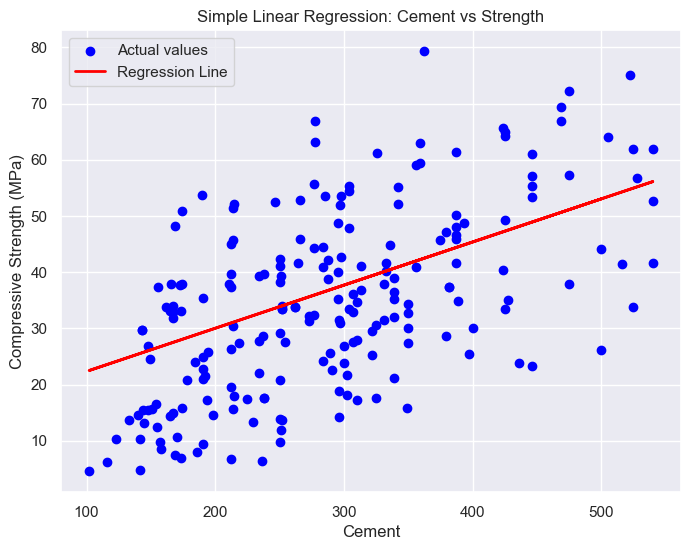

In [11]:
#SOLUTION
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='blue', label='Actual values')
plt.plot(X_test, y_pred_one, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Cement')
plt.ylabel('Compressive Strength (MPa)')
plt.legend()
plt.title('Simple Linear Regression: Cement vs Strength')
plt.show()

In [12]:
#SOLUTION
print(f'Intercept    : {lin_reg_one.intercept_:.3f}')
print(f'Coefficients : {lin_reg_one.coef_}')

Intercept    : 14.664
Coefficients : [0.07674384]


### Task 9 : Linear regression with more predictors

As we see the single feature explains the compressive strength not to well. We continue our search for a better model:
include more than one variable in our regression model. What other 2 features are potential good candidates?
Make predictions for the test set and calculate the Mean Squared Error and R-squared. Print the coefficients and the intercept.

In [13]:
#SOLUTION

# Let's include 'Cement', 'Water', and 'Age' as features based on their correlation with the target variable.

# Select multiple features (X) and the target variable (y)
X = df[['cement', 'water', 'age']]
y = df['csMPa']

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a linear regression model
lin_regML = LinearRegression()

# Train the model
lin_regML.fit(X_train, y_train)

# Predict on the test set
y_predML = lin_regML.predict(X_test)

print(f'R-squared          : {r2_score(y_test, y_predML):.3f}')
print(f'Mean Squared Error : {mean_squared_error(y_test, y_predML):.3f}')
print(f'Intercept          : {lin_regML.intercept_:.3f}')
print(f'Coefficients       : {lin_regML.coef_}')
#SOLUTION_END

R-squared          : 0.500
Mean Squared Error : 128.753
Intercept          : 62.186
Coefficients       : [ 0.06770251 -0.27644885  0.10625113]


---

## scikit-learn machine learning pipeline with model selection and hyperparameter tuning using cross-validation

---